# Cinema Attendance – CA2 Strategic Thinking

## Introduction

This project is about understanding cinema attendance and consumer behaviour. The aim is to explore what influences people's decisions to visit the cinema and whether their answers can help predict cinema attendance patterns.

In CA1, I created a survey and collected the first 33 responses. In this second stage, I will continue working with this data by exploring it in more detail, using different statistical methods and preparing it for further analysis.

The data collection will also continue during the next semester until the end of the project. This means that more responses will be added later, giving me a larger dataset to work with.

In this notebook, I will focus on exploring, analysing and preparing the data collected so far.

In [2]:
# Import pandas
import pandas as pd

# Load the cinema survey dataset
df = pd.read_csv("Data_CA1.csv")

# Display the first 5 rows
df.head()

,attendance_frequency,last_cinema_visit,usual_company,favourite_genre,main_cinema_motivation,usual_spend_band,importance_ticket_price,importance_movie_reviews,importance_movie_genre,importance_cinema_location,importance_screen_sound_quality,importance_comfortable_seating,importance_food_drinks,importance_socialising,likelihood_to_attend_for_desired_release,change_most_likely_to_increase_visits,streaming_preference,suggested_cinema_improvement
0,A few times a year,Within the last month,Partner,Thriller / Mystery,The atmosphere/experience,€10–€14.99,2,5,5,5,5,5,5,5,Very likely,Cheaper food and drinks,I almost always choose streaming over cinema,Not sure
1,A few times a year,3–6 months ago,Partner,Action,Bigger screen and better sound,€15–€19.99,2,3,4,4,4,5,1,3,Likely,Better seats,I usually prefer the cinema but also use strea...,Table service
2,A few times a year,More than 6 months ago,Friends,Thriller / Mystery,Bigger screen and better sound,€15–€19.99,3,4,4,4,4,4,2,3,Likely,Better screens/sound,I don't regularly use streaming services,Ticket prices
3,A few times a year,3–6 months ago,Partner,Horror,It's more immersive,Less than €10,3,3,2,2,2,2,1,2,Neither likely nor unlikely,More interesting movies,I usually prefer streaming but occasionally go...,NaN
4,A few times a year,1–3 months ago,Partner,Action,Socialising with others,€20–€24.99,3,3,3,3,3,3,3,3,Unlikely,Better screens/sound,I usually prefer the cinema but also use strea...,Price


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the column names, data types and missing values
df.info()

Dataset shape: (33, 18)
<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 18 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   attendance_frequency                      33 non-null     str  
 1   last_cinema_visit                         33 non-null     str  
 2   usual_company                             33 non-null     str  
 3   favourite_genre                           33 non-null     str  
 4   main_cinema_motivation                    33 non-null     str  
 5   usual_spend_band                          33 non-null     str  
 6   importance_ticket_price                   33 non-null     int64
 7   importance_movie_reviews                  33 non-null     int64
 8   importance_movie_genre                    33 non-null     int64
 9   importance_cinema_location                33 non-null     int64
 10  importance_screen_sound_quality           33 non-nu

In [4]:
# Check the number of missing values in each column
df.isnull().sum()

attendance_frequency                        0
last_cinema_visit                           0
usual_company                               0
favourite_genre                             0
main_cinema_motivation                      0
usual_spend_band                            0
importance_ticket_price                     0
importance_movie_reviews                    0
importance_movie_genre                      0
importance_cinema_location                  0
importance_screen_sound_quality             0
importance_comfortable_seating              0
importance_food_drinks                      0
importance_socialising                      0
likelihood_to_attend_for_desired_release    0
change_most_likely_to_increase_visits       0
streaming_preference                        0
suggested_cinema_improvement                7
dtype: int64

In [5]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [6]:
# Display the unique answers in each categorical column

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 attendance_frequency
attendance_frequency
A few times a year       21
Less than once a year     5
Once a month              4
Never                     2
2–3 times a month         1
Name: count, dtype: int64

 last_cinema_visit
last_cinema_visit
1–3 months ago              11
Within the last month        9
3–6 months ago               5
More than 6 months ago       4
I can't remember / Never     3
Within the last week         1
Name: count, dtype: int64

 usual_company
usual_company
Partner       13
Friends        9
Alone          4
It depends     3
Children       2
Family         2
Name: count, dtype: int64

 favourite_genre
favourite_genre
Action                        8
Science Fiction / Fantasy     7
Thriller / Mystery            4
Drama                         3
Comedy                        3
Horror                        2
Not answered                  1
Animation                     1
Other / depends on reviews    1
Arthouse                      1
Other / depends             

/var/folders/69/hx68bsws2zd750xbvxwk3gm40000gn/T/ipykernel_59690/4014161736.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [7]:
# Display the unique answers in each categorical column

categorical_columns = df.select_dtypes(include="str").columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 attendance_frequency
attendance_frequency
A few times a year       21
Less than once a year     5
Once a month              4
Never                     2
2–3 times a month         1
Name: count, dtype: int64

 last_cinema_visit
last_cinema_visit
1–3 months ago              11
Within the last month        9
3–6 months ago               5
More than 6 months ago       4
I can't remember / Never     3
Within the last week         1
Name: count, dtype: int64

 usual_company
usual_company
Partner       13
Friends        9
Alone          4
It depends     3
Children       2
Family         2
Name: count, dtype: int64

 favourite_genre
favourite_genre
Action                        8
Science Fiction / Fantasy     7
Thriller / Mystery            4
Drama                         3
Comedy                        3
Horror                        2
Not answered                  1
Animation                     1
Other / depends on reviews    1
Arthouse                      1
Other / depends             

## Looking at the Numerical Data

In this part, I will look at the numerical columns in my dataset. These columns show the ratings that people gave from 1 to 5.

I will use descriptive statistics to check the average ratings and see the lowest and highest answers. This will help me understand how people rated the different cinema factors.

In [8]:
# Select the numerical columns
numerical_columns = df.select_dtypes(include="number")

# Display descriptive statistics
numerical_columns.describe()

,importance_ticket_price,importance_movie_reviews,importance_movie_genre,importance_cinema_location,importance_screen_sound_quality,importance_comfortable_seating,importance_food_drinks,importance_socialising
count,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000
mean,2.878788,3.606061,3.636364,3.636364,3.575758,3.696970,2.666667,3.363636
std,1.139012,0.933387,1.055290,0.962360,1.090593,1.015038,1.241639,1.270290
min,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.000000
50%,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,2.000000,3.000000
75%,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


### What I Found in the Numerical Data

Looking at the results, comfortable seating got the highest average rating, with 3.70 out of 5. Movie genre and cinema location also had high ratings, with an average of 3.64.

Food and drinks had the lowest average rating, with 2.67. Ticket price was also quite low, with an average of 2.88.

From these results, I can see that people in my survey seem to care more about comfortable seats, the movies available and the cinema location. However, I only have 33 responses at the moment. I will collect more answers next semester, so the results could be different later.

## Visualising the Numerical Data

I will now create a bar chart to compare the average ratings for the different cinema factors. This will make it easier to see which factors received higher and lower ratings from the respondents.

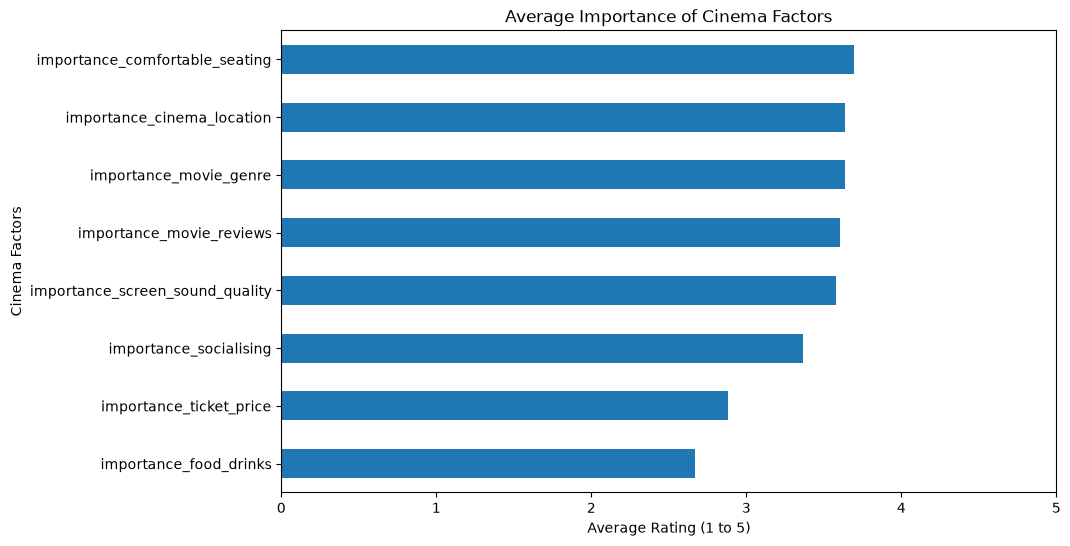

In [9]:
# Import matplotlib
import matplotlib.pyplot as plt

# Calculate the average rating for each factor
average_ratings = numerical_columns.mean().sort_values()

# Create a bar chart
plt.figure(figsize=(10, 6))
average_ratings.plot(kind="barh")

# Add chart labels and title
plt.title("Average Importance of Cinema Factors")
plt.xlabel("Average Rating (1 to 5)")
plt.ylabel("Cinema Factors")
plt.xlim(0, 5)

# Display the chart
plt.show()

### Bar Chart Results

The chart makes it easier to compare the average ratings for each cinema factor. Comfortable seating has the highest average rating, while food and drinks has the lowest.

Movie genre and cinema location also received high ratings. This shows that these factors were important to many of the people who answered my survey.

The chart gives a clearer view of the results and helps me understand which cinema factors people value the most.

## Cinema Attendance Frequency

In this section, I will look at how often the people in my survey go to the cinema. I will use a bar chart to show the number of responses for each attendance frequency.

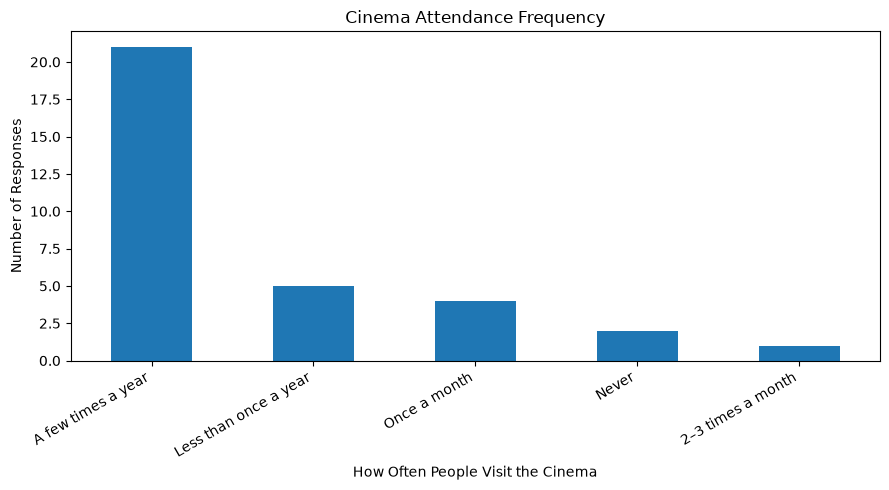

In [10]:
# Count the answers for cinema attendance frequency
attendance_counts = df["attendance_frequency"].value_counts()

# Create a bar chart
plt.figure(figsize=(9, 5))
attendance_counts.plot(kind="bar")

# Add chart labels and title
plt.title("Cinema Attendance Frequency")
plt.xlabel("How Often People Visit the Cinema")
plt.ylabel("Number of Responses")
plt.xticks(rotation=30, ha="right")

# Display the chart
plt.tight_layout()
plt.show()

### Attendance Frequency Results

The chart shows that most people who answered my survey go to the cinema a few times a year. This was the most common answer, with 21 out of 33 responses.

Five people said they go less than once a year, while four people go once a month. Only two people said they never go to the cinema, and one person visits two to three times a month.

This shows that most of the people in my survey are occasional cinema visitors rather than regular visitors.

## Cinema Spending

I will now look at how much people usually spend when they visit the cinema. This can help me understand the spending habits of the people who answered my survey.

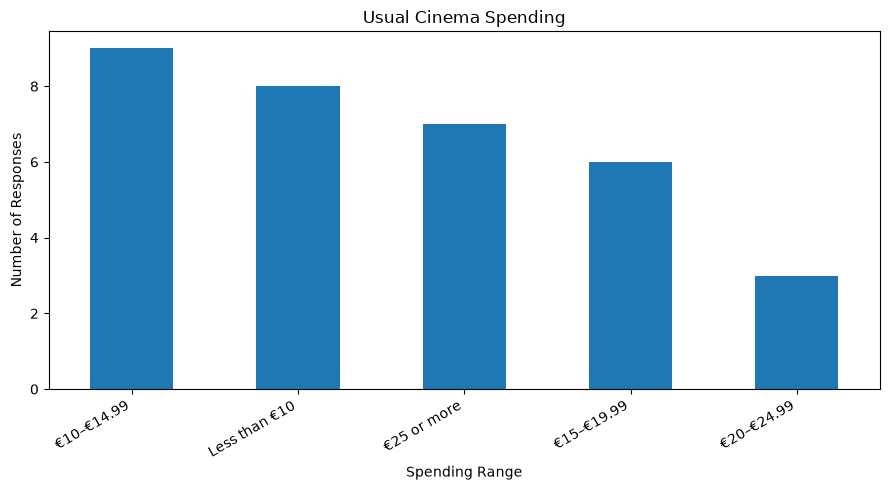

In [11]:
# Count the answers for usual cinema spending
spending_counts = df["usual_spend_band"].value_counts()

# Create a bar chart
plt.figure(figsize=(9, 5))
spending_counts.plot(kind="bar")

# Add chart labels and title
plt.title("Usual Cinema Spending")
plt.xlabel("Spending Range")
plt.ylabel("Number of Responses")
plt.xticks(rotation=30, ha="right")

# Display the chart
plt.tight_layout()
plt.show()

### Cinema Spending Results

The chart shows how much people usually spend when they go to the cinema.

The most common answer was €10–€14.99, with 9 responses. Eight people usually spend less than €10, while 7 people spend €25 or more. Six people spend between €15 and €19.99, and 3 people spend between €20 and €24.99.

This shows that the spending amounts are quite different between the people who answered the survey. Some spend less than €10, while others spend €25 or more.

## Reasons for Going to the Cinema

In this section, I will look at the main reasons why people choose to go to the cinema. This can help me understand what people enjoy about the cinema experience.

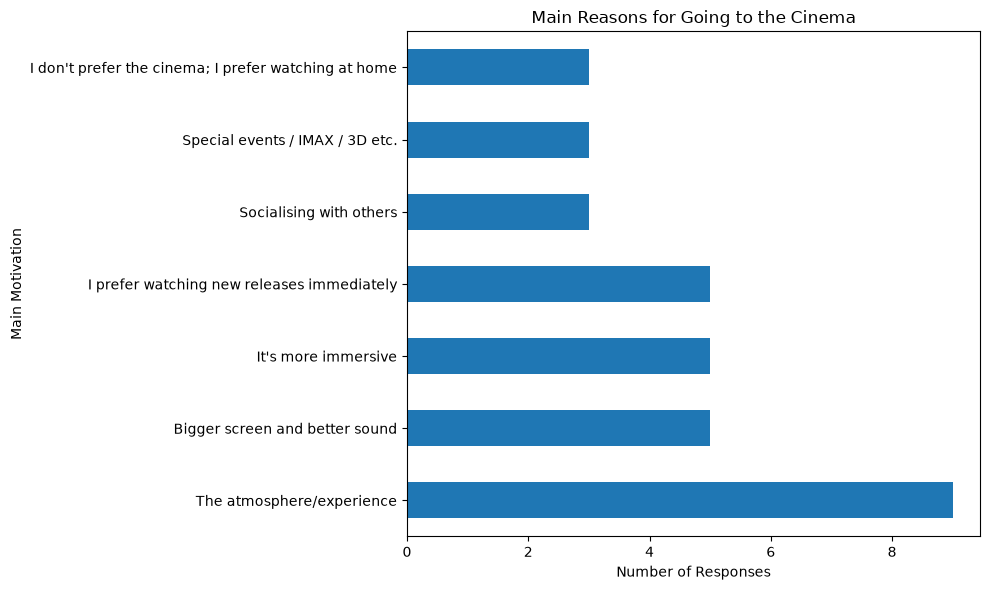

In [12]:
# Count the answers for the main cinema motivation
motivation_counts = df["main_cinema_motivation"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))
motivation_counts.plot(kind="barh")

# Add chart labels and title
plt.title("Main Reasons for Going to the Cinema")
plt.xlabel("Number of Responses")
plt.ylabel("Main Motivation")

# Display the chart
plt.tight_layout()
plt.show()

### Main Reasons for Going to the Cinema

The chart shows that the most common reason for going to the cinema was the atmosphere and experience, with 9 responses.

Other reasons included the bigger screen and better sound, a more immersive experience, and watching new releases as soon as possible. Each of these received 5 responses.

Three people said they prefer watching movies at home instead of going to the cinema.

From these answers, I can see that the cinema experience is an important reason why some people still choose to visit the cinema instead of watching movies at home.

## Cinema and Streaming Preferences

In this section, I will look at whether people prefer watching movies at the cinema or using streaming services. I want to understand if streaming is a reason why some people visit the cinema less often.

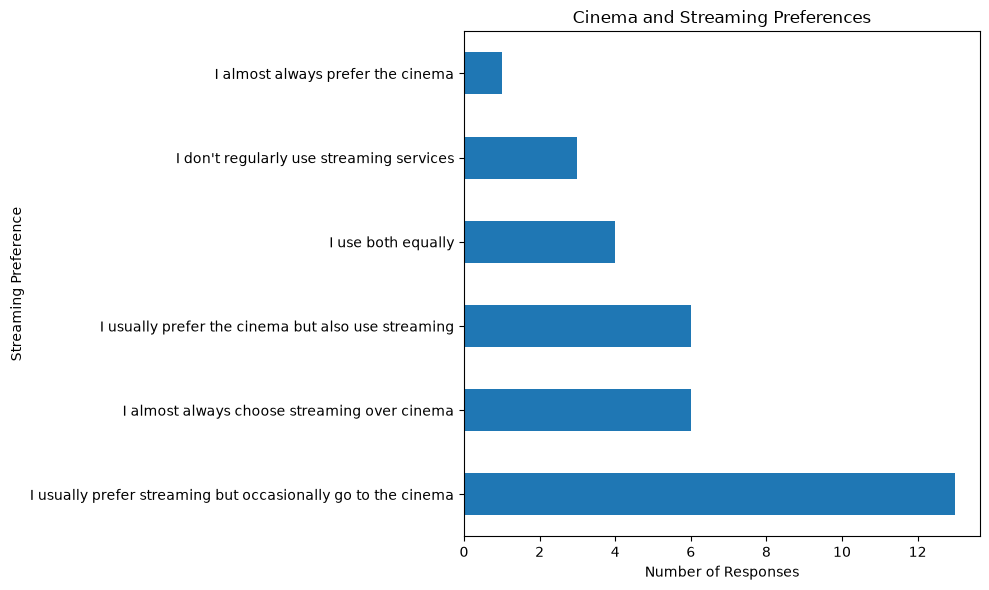

In [13]:
# Count the answers for streaming preferences
streaming_counts = df["streaming_preference"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))
streaming_counts.plot(kind="barh")

# Add chart labels and title
plt.title("Cinema and Streaming Preferences")
plt.xlabel("Number of Responses")
plt.ylabel("Streaming Preference")

# Display the chart
plt.tight_layout()
plt.show()

### Cinema and Streaming Results

The chart shows that 13 people usually prefer streaming but still go to the cinema sometimes (occasionally). Six people almost always choose streaming over the cinema, while another 6 usually prefer going to the cinema but also use streaming services.

Four people said they use both options equally, and 3 do not regularly use streaming services. Only one person almost always prefers the cinema.

These answers show that streaming is a popular choice among the people who completed my survey. However, many of them still go to the cinema from time to time.

## What Could Encourage More Cinema Visits?

In this section, I will look at what could make people go to the cinema more often. This can help me understand what changes or offers people would like to see from cinemas.

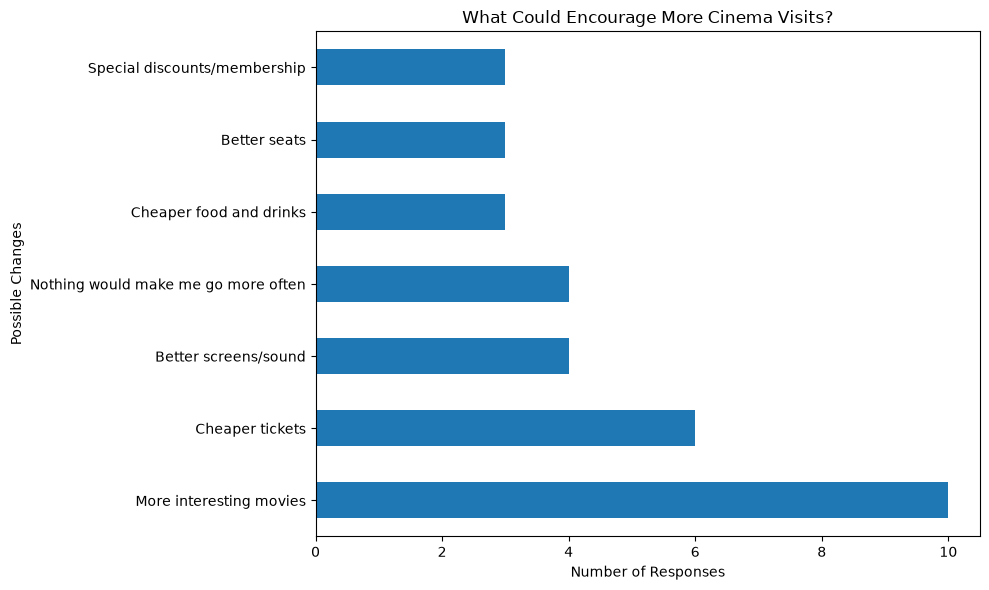

In [14]:
# Count the answers for what could increase cinema visits
change_counts = df["change_most_likely_to_increase_visits"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))
change_counts.plot(kind="barh")

# Add chart labels and title
plt.title("What Could Encourage More Cinema Visits?")
plt.xlabel("Number of Responses")
plt.ylabel("Possible Changes")

# Display the chart
plt.tight_layout()
plt.show()

### Results – What Could Increase Cinema Visits?

The chart shows that more interesting movies was the most popular answer, with 10 people choosing this option.

Six people said cheaper tickets could encourage them to visit more often. Better screens and sound received 4 responses, and another 4 people said that nothing would make them go more often.

Cheaper food and drinks, better seats and special discounts or memberships each received 3 responses.

From these answers, I can see that the movies being shown are an important factor for the people in my survey. Ticket prices are also something that could influence their decision to visit the cinema more often.

## Suggestions for Cinema Improvements

In this section, I will look at the suggestions people gave about how cinemas could improve their experience. This question was optional, so not everyone provided an answer.

In [15]:
# Display the written suggestions, excluding empty answers
suggestions = df["suggested_cinema_improvement"].dropna()

for suggestion in suggestions:
    print("-", suggestion)

- Not sure 
- Table service 
- Ticket prices
- Price
- Hot food
- Small sceeens
- More movie options 
- Sweet popcorn
- Bedseats would be awesome 
- Nothing
- Price
-  Free food and drinks 
- Food from home
- I would make the cinemas shorter 
- Price 
- Image quality
- Price of refreshments
- Nothing to be honest
- Box office performance
- 0
- The times of the showings can be inconvenient for me
- Ticket price 
- In Dublin, better screens! Most of them at very small. 
- Ticket price
- Late hours movies 
- Screen


### Results – Suggestions for Cinema Improvements

The written answers show that people have different ideas about how cinemas could improve their services.

One topic that appeared several times was ticket prices. Some people also mentioned food and drinks, such as having more food options and cheaper refreshments.

Another point was the cinema screens and image quality. Some respondents would like bigger screens and better picture quality. Other suggestions included more movie options and more convenient show times.

Some people did not have any suggestions or were not sure what could be improved.

These answers give me some extra information about what people would like to see from cinemas. I can also use these suggestions when thinking about possible improvements for cinema businesses.

## Comparing Cinema Attendance and Streaming Preferences

I will now compare how often people go to the cinema with their streaming preferences. I want to see if there are any differences between people who visit the cinema more often and those who prefer watching movies at home.

In [16]:
# Compare cinema attendance with streaming preferences
attendance_streaming = pd.crosstab(
    df["attendance_frequency"],
    df["streaming_preference"]
)

# Display the results
attendance_streaming

streaming_preference,I almost always choose streaming over cinema,I almost always prefer the cinema,I don't regularly use streaming services,I use both equally,I usually prefer streaming but occasionally go to the cinema,I usually prefer the cinema but also use streaming
attendance_frequency,,,,,,
2–3 times a month,0,1,0,0,0,0
A few times a year,3,0,2,3,9,4
Less than once a year,2,0,0,0,3,0
Never,1,0,1,0,0,0
Once a month,0,0,0,1,1,2


### Results – Cinema Attendance and Streaming

When comparing cinema attendance with streaming preferences, I noticed that most people who visit the cinema a few times a year usually prefer streaming but still go to the cinema sometimes. This answer was selected by 9 people.

I also noticed that the only person who visits the cinema two to three times a month almost always prefers the cinema.

These results show some differences in cinema and streaming preferences. However, I only have 33 responses so far, so I cannot make strong conclusions from this comparison.

In [17]:
# Import the chi-square test
from scipy.stats import chi2_contingency

# Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(attendance_streaming)

# Display the results
print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

# Check the expected frequencies
print("\nExpected frequencies:")
print(pd.DataFrame(
    expected,
    index=attendance_streaming.index,
    columns=attendance_streaming.columns
))

Chi-square statistic: 47.38612637362638
P-value: 0.0005183639042944489
Degrees of freedom: 20

Expected frequencies:
streaming_preference   I almost always choose streaming over cinema  \
attendance_frequency                                                  
2–3 times a month                                          0.181818   
A few times a year                                         3.818182   
Less than once a year                                      0.909091   
Never                                                      0.363636   
Once a month                                               0.727273   

streaming_preference   I almost always prefer the cinema  \
attendance_frequency                                       
2–3 times a month                               0.030303   
A few times a year                              0.636364   
Less than once a year                           0.151515   
Never                                           0.060606   
Once a month             

### Chi-Square Test

I used the chi-square test to check if there was a relationship between cinema attendance and streaming preferences.

The test gave a p-value of 0.000518. However, when I checked the expected frequencies, I noticed that all of them were below 5. This means that the conditions for using this test were not met.

Because of this, I cannot rely on the p-value or use it to confirm a relationship between the two variables. The results can still be useful for exploring the answers, but a larger dataset may be needed to carry out this test properly.

I plan to collect more survey responses next semester, which will give me more data to work with.

### Spearman's Rank Correlation

I will now use Spearman's rank correlation to check if there is a relationship between cinema attendance frequency and the importance people give to ticket prices.

First, I need to change the attendance answers into numbers because they are currently written as text. This will allow me to compare the two variables.

In [18]:
# Change attendance frequency answers into numbers
attendance_order = {
    "Never": 1,
    "Less than once a year": 2,
    "A few times a year": 3,
    "Once a month": 4,
    "2–3 times a month": 5
}

# Create a new numerical column
df["attendance_numeric"] = df["attendance_frequency"].map(attendance_order)

# Display the attendance answers and their new numerical values
df[["attendance_frequency", "attendance_numeric"]].head(10)

,attendance_frequency,attendance_numeric
0,A few times a year,3
1,A few times a year,3
2,A few times a year,3
3,A few times a year,3
4,A few times a year,3
5,Less than once a year,2
6,Once a month,4
7,A few times a year,3
8,A few times a year,3
9,A few times a year,3


### Spearman Correlation

I will now use the Spearman correlation test to check if there is a relationship between cinema attendance frequency and the importance of ticket prices.

I chose this test because both variables use ordered values. It will help me see if people who visit the cinema more often tend to give different ratings to ticket prices.

In [19]:
# Import the Spearman correlation test
from scipy.stats import spearmanr

# Check the relationship between cinema attendance and ticket price importance
correlation, p_value = spearmanr(
    df["attendance_numeric"],
    df["importance_ticket_price"]
)

# Display the results
print("Spearman correlation:", correlation)
print("P-value:", p_value)

Spearman correlation: -0.1680668217809644
P-value: 0.3498310287136626


### Spearman Correlation Results

The Spearman correlation was -0.168. This shows a weak negative relationship between cinema attendance and the importance of ticket prices.

The p-value was 0.350, which is higher than 0.05. This means that the results do not provide enough evidence of a relationship between these two variables.

Based on my current 33 responses, I cannot say that cinema attendance is related to how important people consider ticket prices. More responses may help me explore this relationship further.

## Cinema Attendance and Likelihood to Attend for a Desired Release

In this section, I will compare how often people visit the cinema with how likely they are to go when a movie they want to watch is released.

I want to see if people who visit the cinema more often are also more likely to go when a new movie interests them.

In [20]:
# Convert likelihood answers into numerical values

likelihood_order = {
    "Very unlikely": 1,
    "Unlikely": 2,
    "Neither likely nor unlikely": 3,
    "Likely": 4,
    "Very likely": 5
}

df["likelihood_numeric"] = df["likelihood_to_attend_for_desired_release"].map(likelihood_order)

# Display the original answers and their numerical values
df[["likelihood_to_attend_for_desired_release", "likelihood_numeric"]].head(10)

,likelihood_to_attend_for_desired_release,likelihood_numeric
0,Very likely,5
1,Likely,4
2,Likely,4
3,Neither likely nor unlikely,3
4,Unlikely,2
5,Neither likely nor unlikely,3
6,Very likely,5
7,Very likely,5
8,Likely,4
9,Likely,4


In [21]:
# Check the relationship between cinema attendance and likelihood to attend
correlation, p_value = spearmanr(
    df["attendance_numeric"],
    df["likelihood_numeric"]
)

# Display the results
print("Spearman correlation:", correlation)
print("P-value:", p_value)

Spearman correlation: 0.6558172489962967
P-value: 3.4265635951748156e-05


### Spearman Correlation Results

The Spearman correlation was 0.656. This shows a positive relationship between cinema attendance and the likelihood of going to the cinema for a desired movie release.

The p-value was 0.0000343, which is lower than 0.05. This means that the results provide statistical evidence of an association between the two variables.

In simple terms, people who visit the cinema more often also tend to be more likely to go when a movie they want to watch is released.

However, I only have 33 responses so far, so I need to be careful when interpreting these results. More responses next semester will help me explore this relationship with a larger dataset.

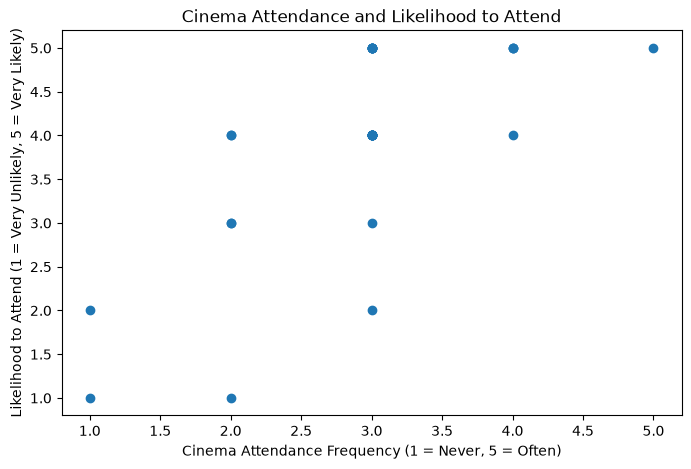

In [22]:
# Create a scatter plot to compare the two variables
plt.figure(figsize=(8, 5))

plt.scatter(
    df["attendance_numeric"],
    df["likelihood_numeric"]
)

# Add chart labels and title
plt.title("Cinema Attendance and Likelihood to Attend")
plt.xlabel("Cinema Attendance Frequency (1 = Never, 5 = Often)")
plt.ylabel("Likelihood to Attend (1 = Very Unlikely, 5 = Very Likely)")

# Display the chart
plt.show()

### Scatter Plot Results

The scatter plot shows the relationship between cinema attendance and the likelihood of attending for a desired movie release.

Each dot represents one person who answered my survey. I can see a general upward pattern in the results. This means that people who visit the cinema more often also tend to be more likely to go when a movie they want to watch is released.

This matches the results of the Spearman correlation test, which showed a positive relationship between the two variables.

## Cinema Factors and Attendance Frequency

In this section, I will explore whether the importance people give to different cinema factors is related to how often they visit the cinema.

I will compare attendance frequency with the eight rating questions from my survey. This will help me see if any of these factors have a stronger relationship with cinema attendance.

In [23]:
# Check the relationship between attendance and each cinema factor

from scipy.stats import spearmanr

# Create an empty list to store the results
correlation_results = []

# Loop through each numerical cinema factor
for column in numerical_columns.columns:
    correlation, p_value = spearmanr(
        df["attendance_numeric"],
        df[column]
    )

    correlation_results.append({
        "Cinema Factor": column,
        "Spearman Correlation": correlation,
        "P-value": p_value
    })

# Display the results in a table
correlation_df = pd.DataFrame(correlation_results)

correlation_df.sort_values(
    by="Spearman Correlation",
    ascending=False
)

,Cinema Factor,Spearman Correlation,P-value
6,importance_food_drinks,0.149812,0.405336
4,importance_screen_sound_quality,0.051177,0.777299
2,importance_movie_genre,0.024739,0.891304
5,importance_comfortable_seating,0.023488,0.896770
3,importance_cinema_location,-0.030859,0.864637
7,importance_socialising,-0.150134,0.404315
0,importance_ticket_price,-0.168067,0.349831
1,importance_movie_reviews,-0.325434,0.064594


### Results of the Cinema Factors Comparison

After comparing the eight cinema factors with attendance frequency, I found that most of the correlation values were quite close to zero. This shows that there were mostly weak relationships between these factors and how often people visit the cinema.

Movie reviews had the strongest negative correlation, with a value of -0.325. However, its p-value was 0.065, which is still higher than 0.05.

All eight p-values were above 0.05. This means that the tests did not provide enough statistical evidence of a relationship between any of these factors and cinema attendance in my current sample.

These results are based on only 33 responses, so I will need more data before making stronger conclusions. I plan to collect more responses next semester and repeat the analysis with the larger dataset.

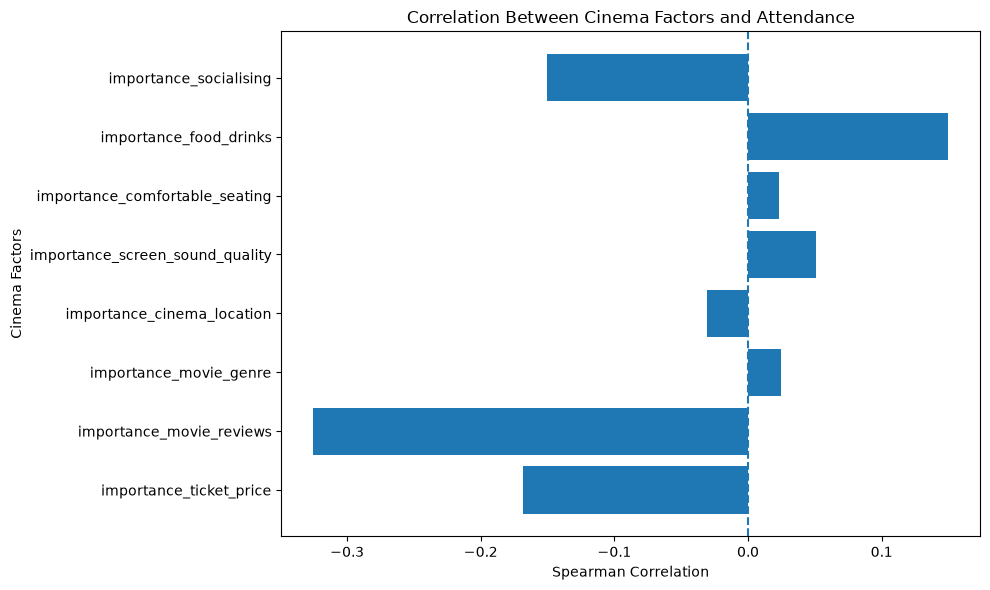

In [24]:
# Create a bar chart to compare the correlation results

plt.figure(figsize=(10, 6))

plt.barh(
    correlation_df["Cinema Factor"],
    correlation_df["Spearman Correlation"]
)

# Add a vertical line at zero
plt.axvline(x=0, linestyle="--")

# Add chart labels and title
plt.title("Correlation Between Cinema Factors and Attendance")
plt.xlabel("Spearman Correlation")
plt.ylabel("Cinema Factors")

# Display the chart
plt.tight_layout()
plt.show()

### Correlation Chart Results

The chart makes it easier to compare the correlation results for the eight cinema factors.

Food and drinks had the highest positive correlation, while movie reviews had the strongest negative correlation with cinema attendance.

However, all the correlation values were quite weak, and none of the p-values were below 0.05.

This means that I did not find enough statistical evidence to show that these cinema factors are related to how often people visit the cinema in my current survey.

More responses next semester may help me understand these relationships better.

## Checking the Numerical Data

Before preparing my dataset, I will check the numerical columns again to make sure the ratings are within the correct range.

The survey used a rating scale from 1 to 5. I will check the lowest and highest values to see if there are any answers outside this range.

In [25]:
# Check the minimum and maximum values of numerical columns

print("Minimum values:")
print(df[numerical_columns.columns].min())

print("\nMaximum values:")
print(df[numerical_columns.columns].max())

Minimum values:
importance_ticket_price            1
importance_movie_reviews           1
importance_movie_genre             1
importance_cinema_location         2
importance_screen_sound_quality    1
importance_comfortable_seating     1
importance_food_drinks             1
importance_socialising             1
dtype: int64

Maximum values:
importance_ticket_price            5
importance_movie_reviews           5
importance_movie_genre             5
importance_cinema_location         5
importance_screen_sound_quality    5
importance_comfortable_seating     5
importance_food_drinks             5
importance_socialising             5
dtype: int64


### Numerical Data Check Results

The results show that all eight cinema factors have values within the expected range of 1 to 5.

The minimum value was 1 for most factors, while cinema location had a minimum value of 2. All factors had a maximum value of 5.

This means that I did not find any values outside the expected rating scale. No corrections were needed for these numerical columns.